# Figure 1

In [4]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_behavioral_data,
    DATASET_CURRENCY,
    LOSS_AVERSION,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions

In [5]:
def plot_accept_stripplot(ax, values, color="#4C72B0", show_ylabel=True, jitter_width=0.15):
    """Vertical violin + jittered stripplot of one dataset's per-subject
    mean acceptance rate, plus a black mean crossbar. The y-axis (ticks +
    spine) is always shown; show_ylabel=False just omits the "Mean
    acceptance rate" text (used so only the leftmost column in a row of
    these carries the label)."""
    x_center = 0.5

    parts = ax.violinplot(values, positions=[x_center], vert=True,
                          showmeans=False, showextrema=False, widths=0.7)
    for body in parts["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor("black")
        body.set_alpha(0.35)

    rng = np.random.default_rng(0)
    jitter = rng.uniform(-jitter_width, jitter_width, size=len(values))
    ax.scatter(np.full(len(values), x_center) + jitter, values,
              color="black", s=60, alpha=0.7, zorder=3,
              edgecolor="black", linewidth=0.5)

    mean_val = np.mean(values)
    ax.plot([x_center - jitter_width * 1.5, x_center + jitter_width * 1.5],
           [mean_val, mean_val], color="black", linewidth=2.5, zorder=4)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if show_ylabel:
        ax.set_ylabel("Mean acceptance rate")


def _fmt_tick(v):
    try:
        return f"{float(v):g}"
    except (ValueError, TypeError):
        return str(v)


def plot_gain_loss_heatmap(ax, hmap_data, dataset, cmap, vmin, vmax, cbar_label,
                           show_loss_aversion=True):
    """Gain (rows) x loss (columns) heatmap, optionally with the gain =
    lambda * loss loss-aversion diagonal. hmap_data: index=loss, columns=gain."""
    losses = hmap_data.index.values.astype(float)
    gains  = hmap_data.columns.values.astype(float)
    hmap_t = hmap_data.T  # rows=gain, columns=loss

    sns.heatmap(
        hmap_t, cmap=cmap, square=True, linewidths=1, linecolor="black",
        vmin=vmin, vmax=vmax, cbar=True, cbar_kws={"label": cbar_label},
        ax=ax, xticklabels=True, yticklabels=True,
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(rotation=90)
    ax.invert_yaxis()  # gain increases from bottom to top

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)

    if show_loss_aversion:
        lambd = LOSS_AVERSION.get(dataset)
        if lambd is not None:
            n_rows, n_cols = len(gains), len(losses)
            loss_endpoints = np.array([losses.min(), losses.max()])
            gain_endpoints = lambd * loss_endpoints
            loss_coords = (
                0.5 + (loss_endpoints - losses.min())
                / (losses.max() - losses.min()) * (n_cols - 1)
            )
            gain_coords = (
                0.5 + (gain_endpoints - gains.min())
                / (gains.max() - gains.min()) * (n_rows - 1)
            )
            ax.plot(loss_coords, gain_coords, color="black", linestyle="--", linewidth=4)

    currency = DATASET_CURRENCY.get(dataset, "")
    ax.set_xlabel(f"Loss ({currency})")
    ax.set_ylabel(f"Gain ({currency})")
    ax.set_xticklabels([_fmt_tick(v) for v in losses])
    ax.set_yticklabels([_fmt_tick(v) for v in gains])

### 3x3 figure: acceptance rate, acceptance grids, RT grids
Columns = datasets. Row 1: mean acceptance rate per subject. Row 2: acceptance rate across gain x loss. Row 3: mean RT across gain x loss.

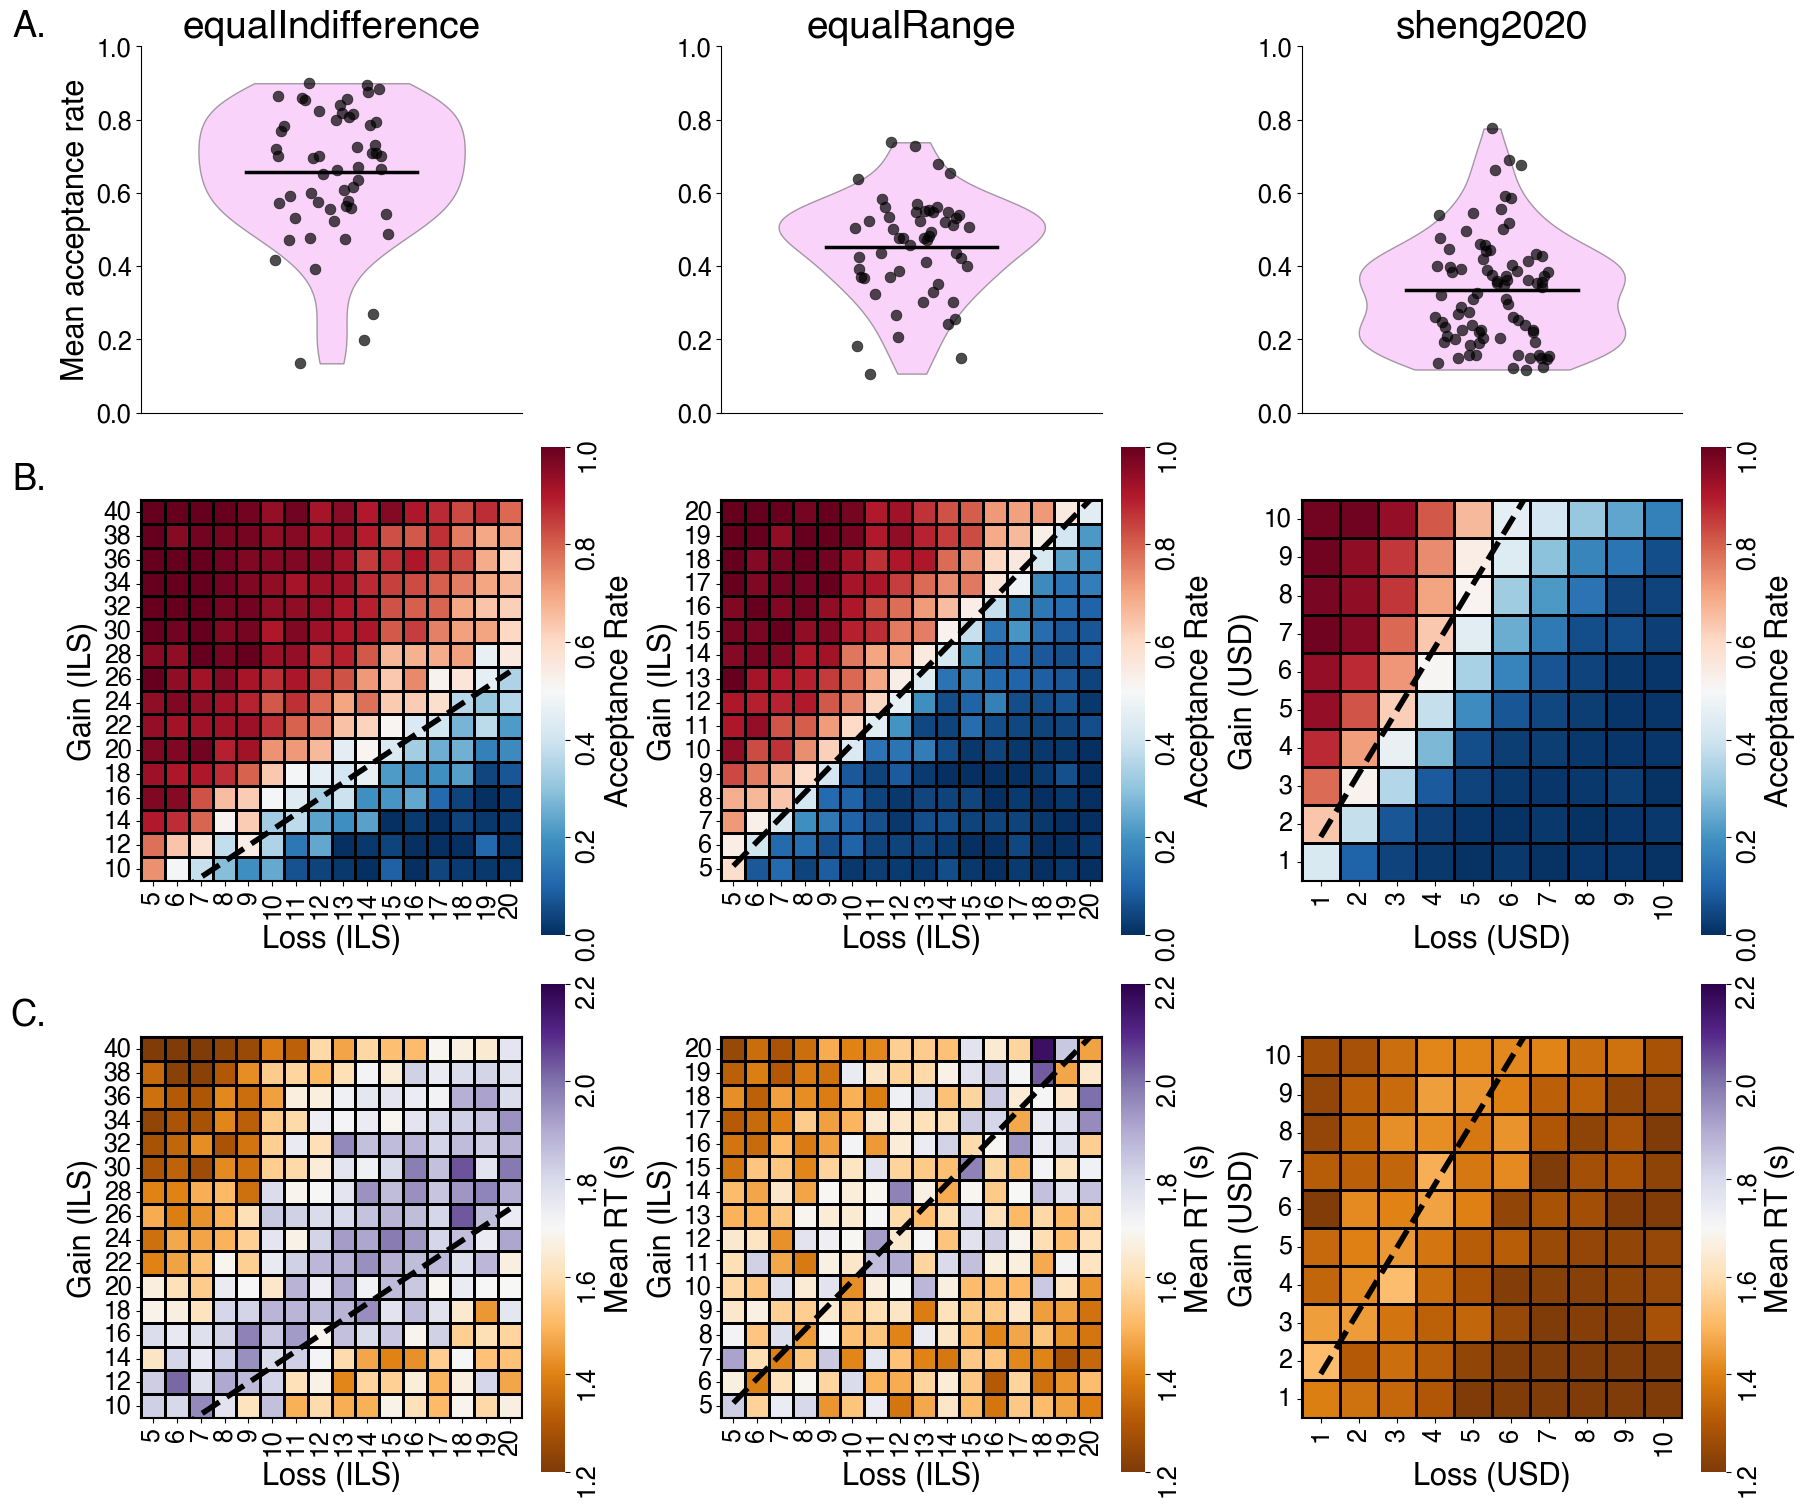

In [6]:
behavior_data = load_behavioral_data()

VIOLIN_COLOR = "violet"
ACCEPT_CMAP = "RdBu_r"
RT_CMAP = "PuOr"
RT_VMIN, RT_VMAX = 1.2, 2.2  # seconds
ROW_LABELS = ["A.", "B.", "C."]

mean_accept = (
    behavior_data.groupby(["dataset", "sub"])["accept"]
    .mean()
    .reset_index(name="mean_accept")
)

accept_hmaps = {}
rt_hmaps = {}
for ds in DATASETS:
    ds_data = behavior_data[behavior_data["dataset"] == ds]
    subj_cell_means = (
        ds_data.groupby(["sub", "loss", "gain"])[["accept", "rt"]]
        .mean()
        .reset_index()
    )
    accept_hmaps[ds] = subj_cell_means.groupby(["loss", "gain"])["accept"].mean().unstack()
    rt_hmaps[ds] = subj_cell_means.groupby(["loss", "gain"])["rt"].mean().unstack()

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15), layout="constrained",
                         gridspec_kw={"height_ratios": [1.5, 2, 2]})

for col, ds in enumerate(DATASETS):
    values = mean_accept[mean_accept["dataset"] == ds]["mean_accept"].values
    plot_accept_stripplot(axes[0, col], values, color=VIOLIN_COLOR, show_ylabel=(col == 0))
    axes[0, col].set_title(DATASET_LABELS.get(ds, ds))

    plot_gain_loss_heatmap(
        axes[1, col], accept_hmaps[ds], ds,
        cmap=ACCEPT_CMAP, vmin=0, vmax=1, cbar_label="Acceptance Rate",
    )

    plot_gain_loss_heatmap(
        axes[2, col], rt_hmaps[ds], ds,
        cmap=RT_CMAP, vmin=RT_VMIN, vmax=RT_VMAX, cbar_label="Mean RT (s)",
    )

# Row labels, placed just outside the top-left corner of each row's leftmost panel
for row, label in enumerate(ROW_LABELS):
    axes[row, 0].text(-0.25, 1.1, label, transform=axes[row, 0].transAxes,
                      fontsize=26, fontweight="bold", va="top", ha="right")


fig.savefig("saved/figure1.svg", dpi=300, bbox_inches="tight")
plt.show()